In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import glob
from scipy.integrate import cumulative_trapezoid

## List files to convert

In [16]:
das_files = glob.glob('../../../DAS/das_gunnuhver/no_med_strainrate/*_*.h5')

In [17]:
das_files.sort()

In [18]:
das_files

['../../../DAS/das_gunnuhver/no_med_strainrate/1_aug1_sep1_tmed_ch_2000_2150.h5',
 '../../../DAS/das_gunnuhver/no_med_strainrate/2_sep15_dec1_tmed_ch_2000_2150.h5',
 '../../../DAS/das_gunnuhver/no_med_strainrate/3_feb13_may19_tmed_ch_2000_2150.h5']

In [19]:
n = 2
das = xr.open_dataset(das_files[n])

In [20]:
das.data

<xarray.DataArray 'data' (phony_dim_0: 150, phony_dim_1: 817396)> Size: 490MB
[122609400 values with dtype=float32]
Dimensions without coordinates: phony_dim_0, phony_dim_1
Attributes:
    begin_time:  2025-02-13T09:52:17+00:00
    dt_s:        10.0
    dx_m:        10.213001907746815
    end_time:    2025-05-19T00:24:57+00:00
    t0_s:        0.0
    unit:        microstrain/s
    processing:  source already LP 0-0.01 Hz; +7-channel shift to QuantX tapt...

In [8]:
time = np.arange(np.datetime64(das.data.begin_time,"s"),np.datetime64(das.data.end_time,"s"), int(das.data.dt_s))

/tmp/ipykernel_153853/109884244.py:1: DeprecationWarning: parsing timezone aware datetimes is deprecated; this will raise an error in the future
  time = np.arange(np.datetime64(das.data.begin_time,"s"),np.datetime64(das.data.end_time,"s"), int(das.data.dt_s))


In [10]:
len(time), len(das.data[0,:])

(817396, 817396)

In [11]:
channels = np.arange(2000,2150)

## Convert strain rate to strain

In [12]:
das_strain = cumulative_trapezoid(das.data, dx=das.data.dt_s)

## Exporting the data in strain

In [14]:
ds = xr.Dataset(
    {
        "strain": (("channel", "time"), das_strain),
    },
    coords={
        "time": time[:-1],
        "channel": channels,
    },
)

/tmp/ipykernel_153853/4248993708.py:1: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = xr.Dataset(


In [114]:
ds.to_netcdf('./no_med_strain/%i_das_strain_%s_%s.h5'% (n+1, np.datetime64(das.data.begin_time, 's'), 
                                                        np.datetime64(das.data.end_time, 's')))

/tmp/ipykernel_151303/3202015712.py:1: DeprecationWarning: parsing timezone aware datetimes is deprecated; this will raise an error in the future
  ds.to_netcdf('./no_med_strain/%i_das_strain_%s_%s.h5'% (n+1, np.datetime64(das.data.begin_time, 's'),
/tmp/ipykernel_151303/3202015712.py:2: DeprecationWarning: parsing timezone aware datetimes is deprecated; this will raise an error in the future
  np.datetime64(das.data.end_time, 's')))


### Plot

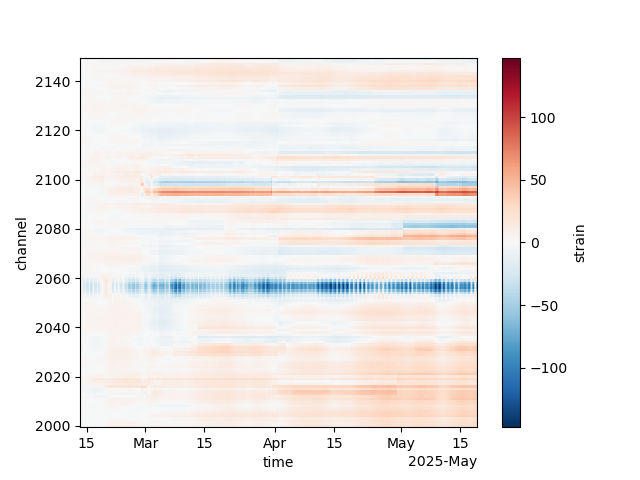

In [ ]:
%matplotlib inline 
plt.figure()
ds.strain.sel(channel=slice(2070,2080)).median(dim="channel").plot()
plt.show()